# Temporal Analysis of Spotify Tracks

This notebook studies how track counts and audio features vary by release year. The yearly averages describe this dataset; they do not prove that release year caused a change in music or popularity.

## 1. Import libraries

Pandas reads and summarizes the table. Matplotlib saves the graphs as image files.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt


## 2. Load the dataset

The notebook reads the cleaned copy. The raw CSV is preserved separately. Exact duplicate rows were removed and confirmed invalid sentinel measurements were marked as missing; no values were filled in.

In [2]:
df = pd.read_csv('../data/processed/cleaned_spotify_tracks.csv')


## 3. Display the first five rows

In [3]:
print(df.head())


                 track_id  ... language
0  2r0ROhr7pRN4MXDMT1fEmd  ...    Tamil
1  4I38e6Dg52a2o2a8i5Q5PW  ...    Tamil
2  59NoiRhnom3lTeRFaBzOev  ...    Tamil
3  5uUqRQd385pvLxC8JX3tXn  ...    Tamil
4  1KaBRg2xgNeCljmyxBH1mo  ...    Tamil

[5 rows x 22 columns]


## 4. Understand the dataset

In [4]:
print('Rows and columns:', df.shape)
print('Column names:', list(df.columns))
print(df.dtypes)
print('Missing values:', df.isna().sum().sum())
print('Duplicate rows:', df.duplicated().sum())
print('Duplicate track IDs:', df['track_id'].duplicated().sum())


Rows and columns: (62239, 22)
Column names: ['track_id', 'track_name', 'artist_name', 'year', 'popularity', 'artwork_url', 'album_name', 'acousticness', 'danceability', 'duration_ms', 'energy', 'instrumentalness', 'key', 'liveness', 'loudness', 'mode', 'speechiness', 'tempo', 'time_signature', 'valence', 'track_url', 'language']
track_id                str
track_name              str
artist_name             str
year                  int64
popularity            int64
artwork_url             str
album_name              str
acousticness        float64
danceability        float64
duration_ms         float64
energy              float64
instrumentalness    float64
key                 float64
liveness            float64
loudness            float64
mode                float64
speechiness         float64
tempo               float64
time_signature      float64
valence             float64
track_url               str
language                str
dtype: object
Missing values: 420
Duplicate rows: 0
D

## 5. Prepare the year column

The source stores year as a number. Convert it to numeric safely, then check which rows have a valid year. We keep only years present in the CSV; we do not fill missing years.

In [5]:
df['year'] = pd.to_numeric(df['year'], errors='coerce')
df = df.dropna(subset=['year'])
df['year'] = df['year'].astype(int)
print('Year range:', df['year'].min(), 'to', df['year'].max())


Year range: 1971 to 2024


## 6. Calculate yearly track counts

`groupby` collects rows with the same year, and `count` counts track IDs in each group.

In [6]:
yearly_track_count = df.groupby('year')['track_id'].count().sort_index()
print(yearly_track_count)


year
1971      12
1972      21
1973      62
1974      10
1975      19
1976       9
1977      39
1978      14
1979      46
1980      20
1981      37
1982     164
1983     176
1984     213
1985     256
1986     260
1987     210
1988     230
1989     297
1990     416
1991     268
1992     405
1993     366
1994     522
1995     457
1996     306
1997     412
1998     292
1999     296
2000     376
2001     493
2002     494
2003     594
2004     527
2005     854
2006     786
2007     865
2008     977
2009    1182
2010    1588
2011    1621
2012    1965
2013    3362
2014    2787
2015    2626
2016    2821
2017    2896
2018    2971
2019    2807
2020    3035
2021    3698
2022    5181
2023    6427
2024    5471
Name: track_id, dtype: int64


## 7. Calculate yearly average popularity

We calculate both the mean and median because a few popular tracks can pull the mean upward. Track count shows how many rows support each yearly result.

In [7]:
yearly_popularity = df.groupby('year').agg(
    average_popularity=('popularity', 'mean'),
    median_popularity=('popularity', 'median'),
    track_count=('track_id', 'count')
).sort_index()
print(yearly_popularity.head())


      average_popularity  median_popularity  track_count
year                                                    
1971           30.666667               31.0           12
1972           26.809524               24.0           21
1973           27.064516               22.5           62
1974           31.000000               30.5           10
1975           37.368421               37.0           19


## 8. Calculate yearly average energy

In [8]:
yearly_energy = df.groupby('year')['energy'].mean().sort_index()
print(yearly_energy.head())


year
1971    0.332800
1972    0.585905
1973    0.568048
1974    0.565290
1975    0.678789
Name: energy, dtype: float64


## 9. Calculate yearly average danceability

In [9]:
yearly_danceability = df.groupby('year')['danceability'].mean().sort_index()
print(yearly_danceability.head())


year
1971    0.467250
1972    0.534714
1973    0.502290
1974    0.523000
1975    0.478421
Name: danceability, dtype: float64


## 10. Calculate yearly average valence

Valence is Spotify's estimate of the positive or happy character conveyed by a track. It is an audio feature, not a direct survey of listeners' feelings.

In [10]:
yearly_valence = df.groupby('year')['valence'].mean().sort_index()
print(yearly_valence.head())


year
1971    0.397050
1972    0.722048
1973    0.533889
1974    0.502420
1975    0.597632
Name: valence, dtype: float64


## 11. Generate graphs

The first chart includes every year represented in the data. For trend charts, years with fewer than 30 tracks are shown as faint markers and excluded from the connected line, because their averages are less stable. The threshold is a display rule, not a data correction.

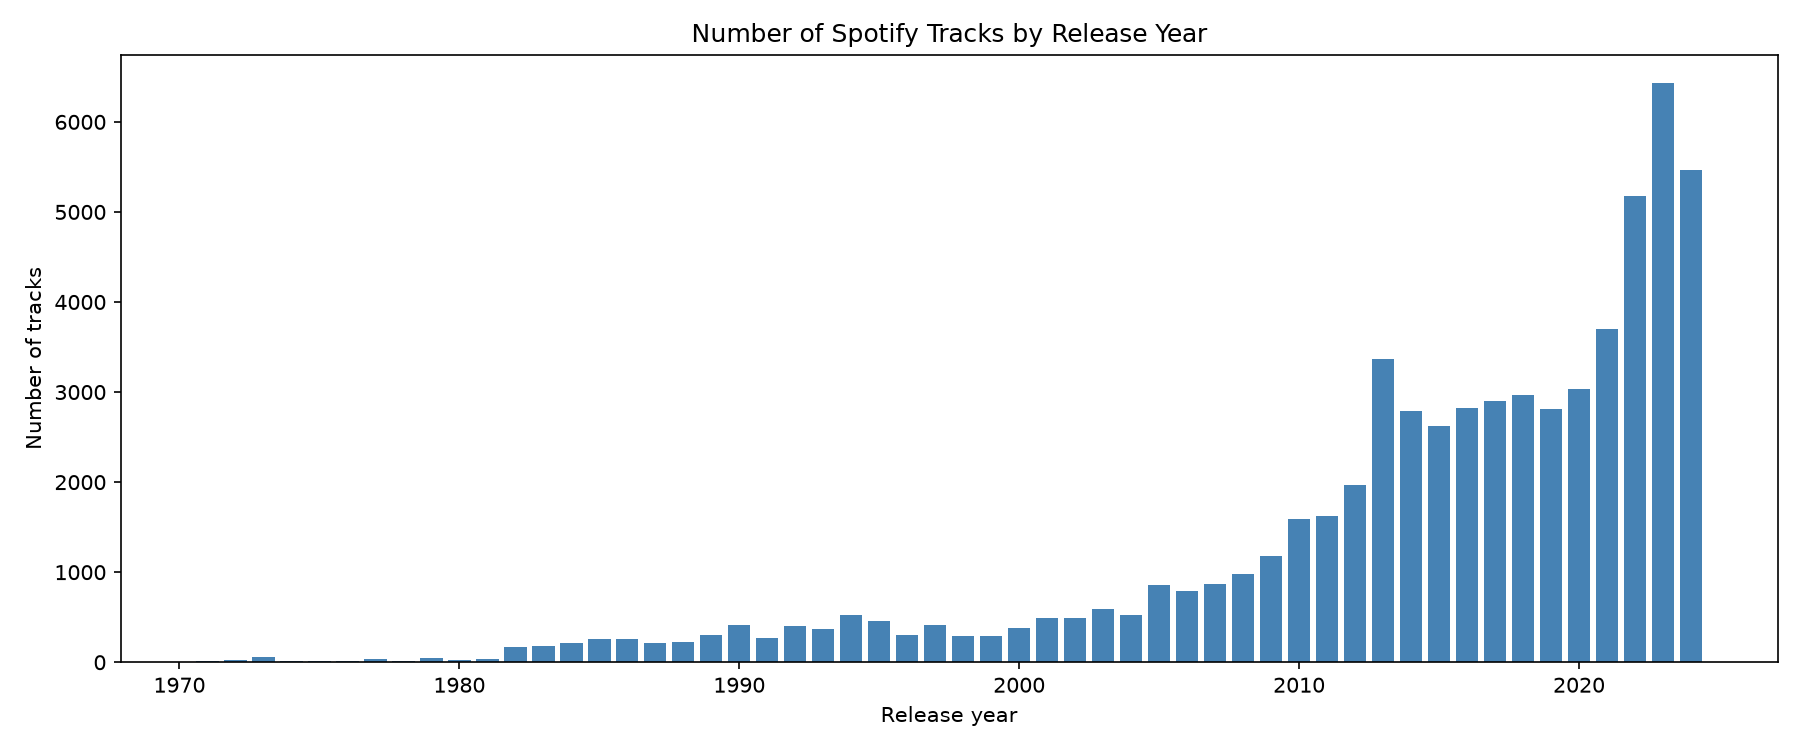

In [11]:
minimum_tracks = 30
reliable_years = yearly_track_count[yearly_track_count >= minimum_tracks].index

plt.figure(figsize=(12, 5))
plt.bar(yearly_track_count.index, yearly_track_count.values, color='steelblue')
plt.title('Number of Spotify Tracks by Release Year')
plt.xlabel('Release year')
plt.ylabel('Number of tracks')
plt.tight_layout()
plt.savefig('../outputs/graphs/temporal/yearly_track_count.png', dpi=150)
plt.show(block=False)
plt.close()


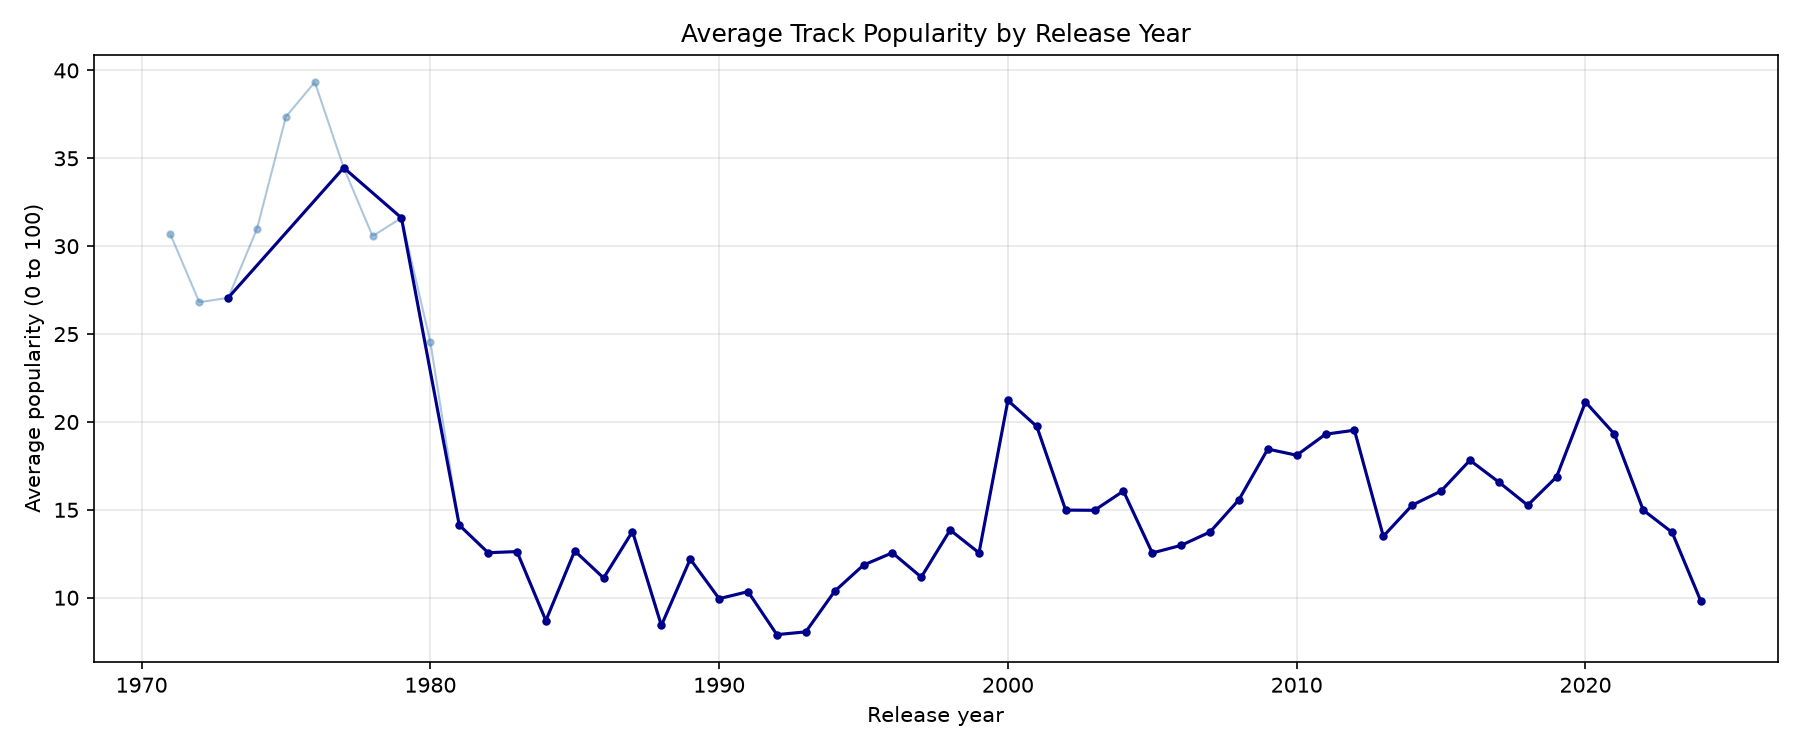

In [12]:
plt.figure(figsize=(12, 5))
plt.plot(yearly_popularity['average_popularity'].index, yearly_popularity['average_popularity'].values, color='steelblue', marker='o', markersize=3, linewidth=1, alpha=0.45)
plt.plot(reliable_years, yearly_popularity['average_popularity'].loc[reliable_years], color='darkblue', marker='o', markersize=3, linewidth=1.5)
plt.title('Average Track Popularity by Release Year')
plt.xlabel('Release year')
plt.ylabel('Average popularity (0 to 100)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('../outputs/graphs/temporal/yearly_average_popularity.png', dpi=150)
plt.show(block=False)
plt.close()


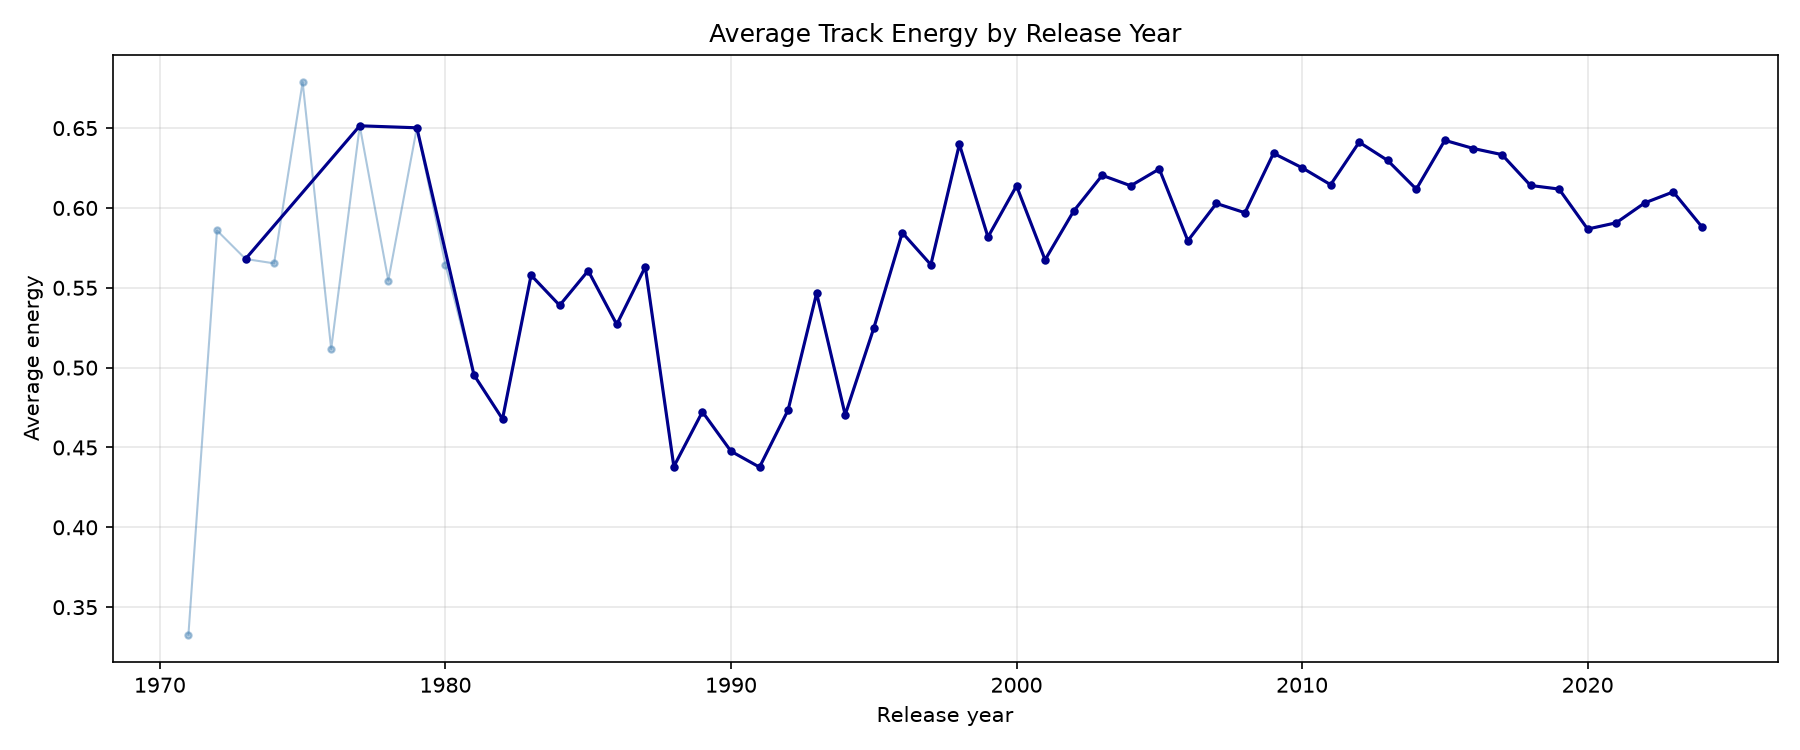

In [13]:
plt.figure(figsize=(12, 5))
plt.plot(yearly_energy.index, yearly_energy.values, color='steelblue', marker='o', markersize=3, linewidth=1, alpha=0.45)
plt.plot(reliable_years, yearly_energy.loc[reliable_years], color='darkblue', marker='o', markersize=3, linewidth=1.5)
plt.title('Average Track Energy by Release Year')
plt.xlabel('Release year')
plt.ylabel('Average energy')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('../outputs/graphs/temporal/yearly_average_energy.png', dpi=150)
plt.show(block=False)
plt.close()


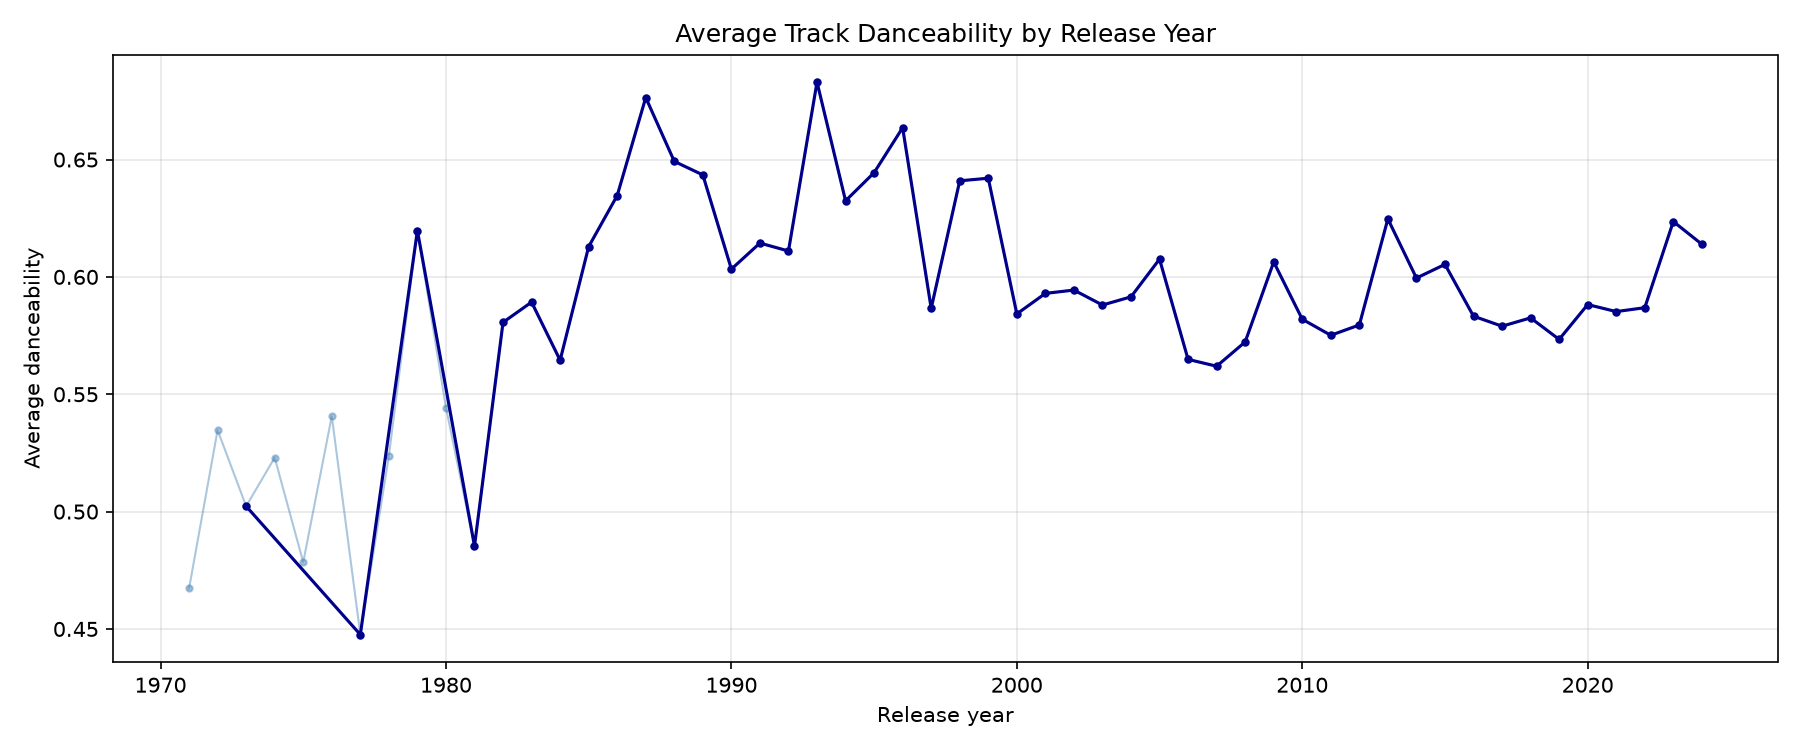

In [14]:
plt.figure(figsize=(12, 5))
plt.plot(yearly_danceability.index, yearly_danceability.values, color='steelblue', marker='o', markersize=3, linewidth=1, alpha=0.45)
plt.plot(reliable_years, yearly_danceability.loc[reliable_years], color='darkblue', marker='o', markersize=3, linewidth=1.5)
plt.title('Average Track Danceability by Release Year')
plt.xlabel('Release year')
plt.ylabel('Average danceability')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('../outputs/graphs/temporal/yearly_average_danceability.png', dpi=150)
plt.show(block=False)
plt.close()


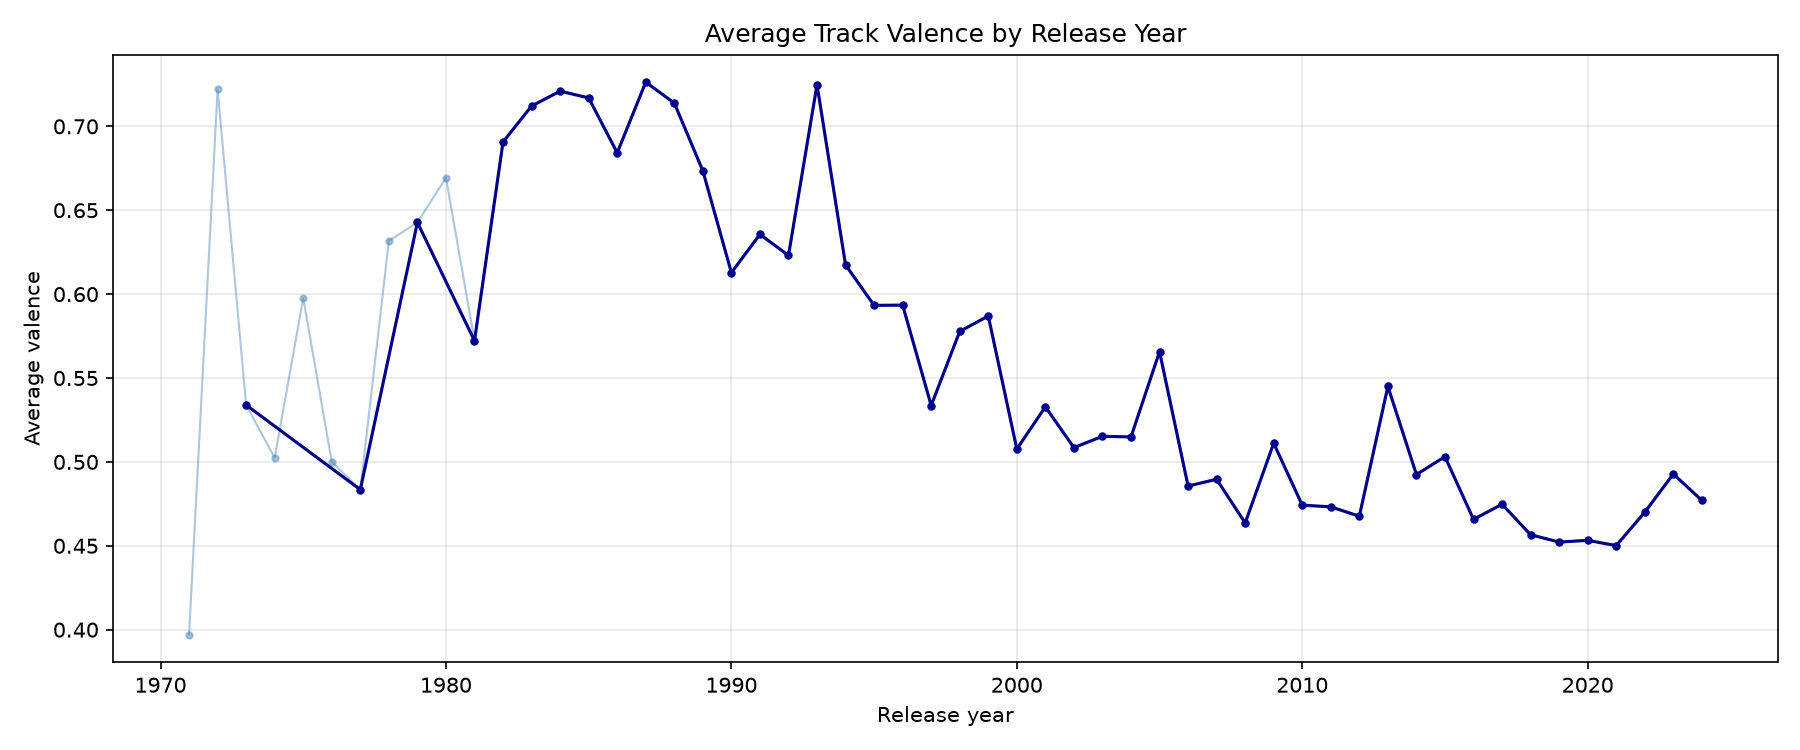

In [15]:
plt.figure(figsize=(12, 5))
plt.plot(yearly_valence.index, yearly_valence.values, color='steelblue', marker='o', markersize=3, linewidth=1, alpha=0.45)
plt.plot(reliable_years, yearly_valence.loc[reliable_years], color='darkblue', marker='o', markersize=3, linewidth=1.5)
plt.title('Average Track Valence by Release Year')
plt.xlabel('Release year')
plt.ylabel('Average valence')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('../outputs/graphs/temporal/yearly_average_valence.png', dpi=150)
plt.show(block=False)
plt.close()


## 12. Print important findings

In [16]:
print('Year with the most tracks:', int(yearly_track_count.idxmax()), '-', int(yearly_track_count.max()), 'tracks')
print('Year with the fewest tracks:', int(yearly_track_count.idxmin()), '-', int(yearly_track_count.min()), 'tracks')
print('Yearly popularity average uses the track_count column above.')
print('Years with fewer than', minimum_tracks, 'tracks:', list(yearly_track_count[yearly_track_count < minimum_tracks].index))


Year with the most tracks: 2023 - 6427 tracks
Year with the fewest tracks: 1976 - 9 tracks
Yearly popularity average uses the track_count column above.
Years with fewer than 30 tracks: [1971, 1972, 1974, 1975, 1976, 1978, 1980]


## 13. Combined normalized audio-feature trend

Energy, danceability and valence share a similar 0-to-1 scale in this dataset. Popularity uses a different 0-to-100 scale, so it is left out of this combined chart. Each feature is normalized to its own 1971-2024 range so that changes in shape can be compared; the vertical values are not original feature scores.

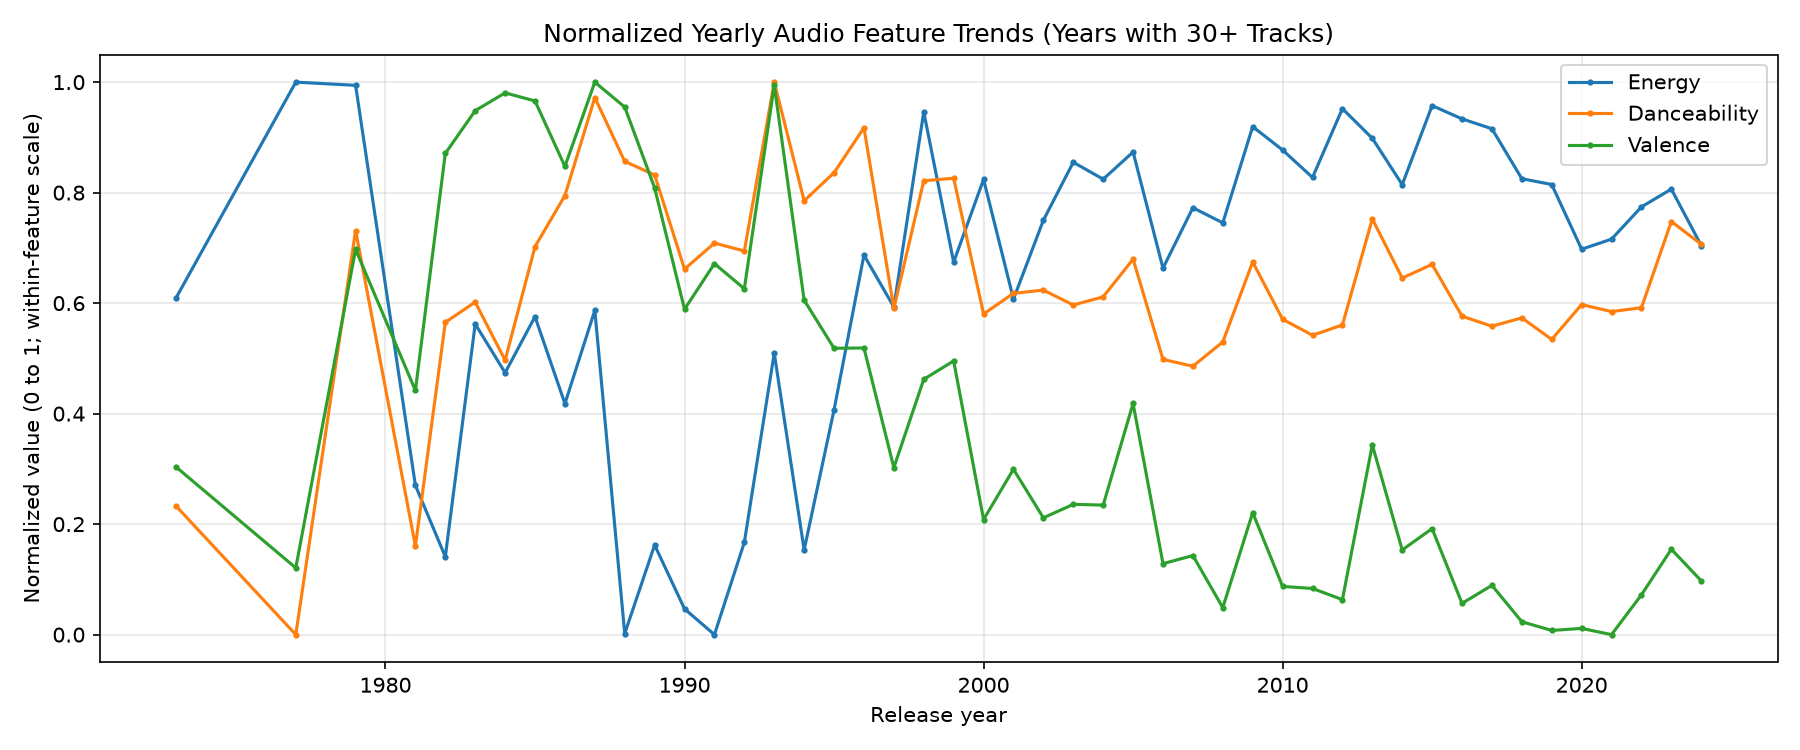

In [17]:
combined_features = pd.DataFrame({
    'Energy': yearly_energy,
    'Danceability': yearly_danceability,
    'Valence': yearly_valence
})
combined_features = combined_features.loc[reliable_years]
normalized_features = (combined_features - combined_features.min()) / (combined_features.max() - combined_features.min())

plt.figure(figsize=(12, 5))
for column in normalized_features.columns:
    plt.plot(normalized_features.index, normalized_features[column], marker='o', markersize=2, label=column)
plt.title('Normalized Yearly Audio Feature Trends (Years with 30+ Tracks)')
plt.xlabel('Release year')
plt.ylabel('Normalized value (0 to 1; within-feature scale)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('../outputs/graphs/temporal/combined_temporal_features.png', dpi=150)
plt.show(block=False)
plt.close()


## 14. Conclusions

The plots describe the dataset's release-year composition and the average features of tracks represented in each year. Track counts are uneven, and historical averages can reflect which songs were included, how popularity was measured, and how the dataset was assembled. They should guide questions for further research, not be treated as forecasts or causal explanations.